# 04. Run Coupled Multi-Reservoir Cascade (Xindian River)

- **Step 4 of 4:** Run full-year 2025 cascades (`feitsui -> zhitan -> xindian_outlet`), verify closed mass balance & Lohmann routing, and inspect Typhoon Podul joint dispatch.
- **Note (Repo-Only — Not in Paper):** Uses TFRA & MOEA/WRA official records (`0` API cost offline replay).

In [1]:
import json, tempfile
from pathlib import Path
import sys
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

for p in (Path.cwd(), *Path.cwd().parents):
    if (p / "tutorials" / "_helpers.py").is_file():
        sys.path.insert(0, str(p))
        break
from tutorials import _helpers as h

REPO_ROOT = h.find_repo_root()
C = h.configure_plots()

## 1. Execute Rule-Based vs. Hybrid LLM Cascades (`2025`)

Run dual Hanasaki (`rule_based.yaml`) and Feitsui LLM + Zhitan Hanasaki (`hybrid_llm.yaml`) across all 365 days of 2025 and verify closure.

In [2]:
with tempfile.TemporaryDirectory() as td:
    xd = h.replay_xindian_2025(REPO_ROOT, Path(td))

print("Offline verify_run  :", {k: v["status"] for k, v in xd["verifications"].items()})
print(f"UH convolution diff : {xd['max_routing_diff_cms']:.2e} m3/s (exact parity)")
print(xd["scores"].round(3).to_string(index=False))



Offline verify_run  : {'rule_based': 'PASS', 'hybrid_llm': 'PASS'}
UH convolution diff : 2.27e-13 m3/s (exact parity)
 condition        quantity   kge     r  alpha  beta    nse   rmse
rule_based   Feitsui level 0.915 0.918  1.014 0.981  0.358  3.634
rule_based Feitsui release 0.447 0.480  0.835 1.093  0.100 37.626
rule_based Downstream flow 0.760 0.823  1.148 1.066  0.568 57.481
hybrid_llm   Feitsui level 0.601 0.845  0.633 1.012  0.498  3.213
hybrid_llm Feitsui release 0.460 0.562  1.314 1.040 -0.250 44.346
hybrid_llm Downstream flow 0.690 0.857  1.271 1.043  0.562 57.919


## 2. Visualize Typhoon Storm Joint Dispatch (`2025`)

Zoom into the largest 2025 Nanshi lateral inflow peak (Typhoon Podul) to inspect upstream Feitsui pre-throttling and downstream outlet flow.

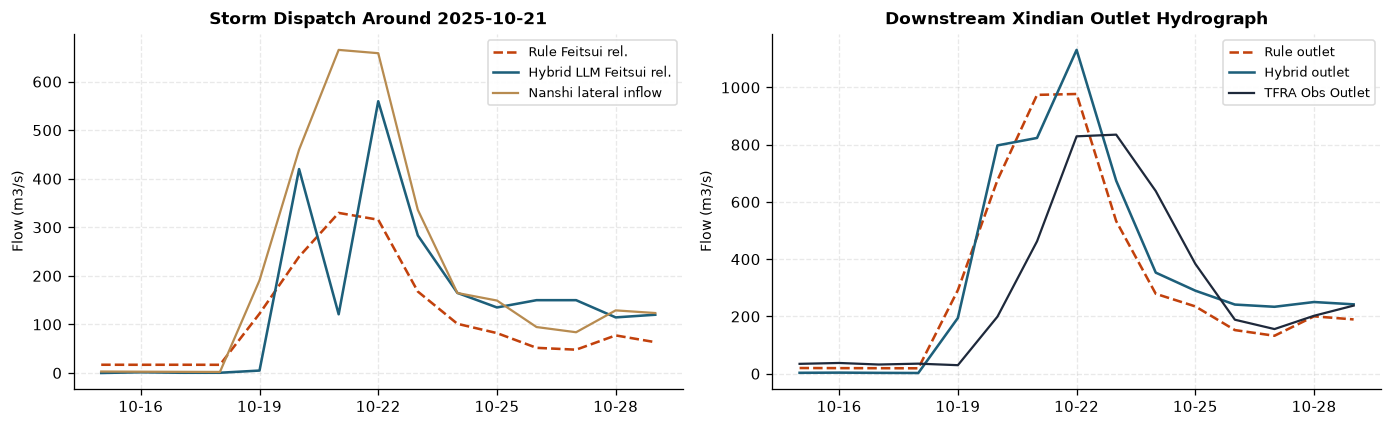

In [3]:
r_fl, h_fl = xd["rule_flows"], xd["hybrid_flows"]
zh_lat = h_fl[h_fl["node"] == "zhitan_local"].copy()
zh_lat["date_dt"] = pd.to_datetime(zh_lat["date_key"])
peak_dt = zh_lat.loc[zh_lat["local_inflow_cms"].idxmax(), "date_dt"]
w0, w1 = peak_dt - pd.Timedelta(days=6), peak_dt + pd.Timedelta(days=8)

r_tr, h_tr = xd["rule_traj"], xd["hybrid_traj"]
for df in (r_tr, h_tr, r_fl, h_fl):
    df["date_dt"] = pd.to_datetime(df["date_key"])

fig, axes = plt.subplots(1, 2, figsize=(12.2, 3.8))
for df, col, ls, lbl in [(r_tr, C["coral"], "--", "Rule Feitsui rel."), (h_tr, C["teal"], "-", "Hybrid LLM Feitsui rel.")]:
    sub = df[(df["reservoir_id"] == "feitsui") & (df["date_dt"].between(w0, w1))]
    axes[0].plot(sub["date_dt"], sub["total_outflow_cms"], color=col, ls=ls, lw=1.6, label=lbl)
sub_lat = zh_lat[zh_lat["date_dt"].between(w0, w1)]
axes[0].plot(sub_lat["date_dt"], sub_lat["local_inflow_cms"], color=C["gold"], lw=1.4, label="Nanshi lateral inflow")
axes[0].set_title(f"Storm Dispatch Around {peak_dt.strftime('%Y-%m-%d')}"); axes[0].set_ylabel("Flow (m3/s)"); axes[0].legend(fontsize=8)

for df, col, ls, lbl in [(r_fl, C["coral"], "--", "Rule outlet"), (h_fl, C["teal"], "-", "Hybrid outlet")]:
    sub = df[(df["node"] == "xindian_outlet") & (df["date_dt"].between(w0, w1))]
    axes[1].plot(sub["date_dt"], sub["routed_flow_cms"], color=col, ls=ls, lw=1.6, label=lbl)
obs_w = xd["observations"][xd["observations"]["date_dt"].between(w0, w1)]
axes[1].plot(obs_w["date_dt"], obs_w["downstream_flow_cms"], color=C["obs"], lw=1.4, label="TFRA Obs Outlet")
axes[1].set_title("Downstream Xindian Outlet Hydrograph"); axes[1].set_ylabel("Flow (m3/s)"); axes[1].legend(fontsize=8)
for ax in axes:
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=3)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
plt.tight_layout(); plt.show()

## 3. Full-Year `2025` Elevation vs. MOEA/WRA Rule Curve & Flows

Inspect Feitsui Reservoir levels against the official MOEA/WRA 36-dekad rule curve alongside downstream flows at `xindian_outlet`.

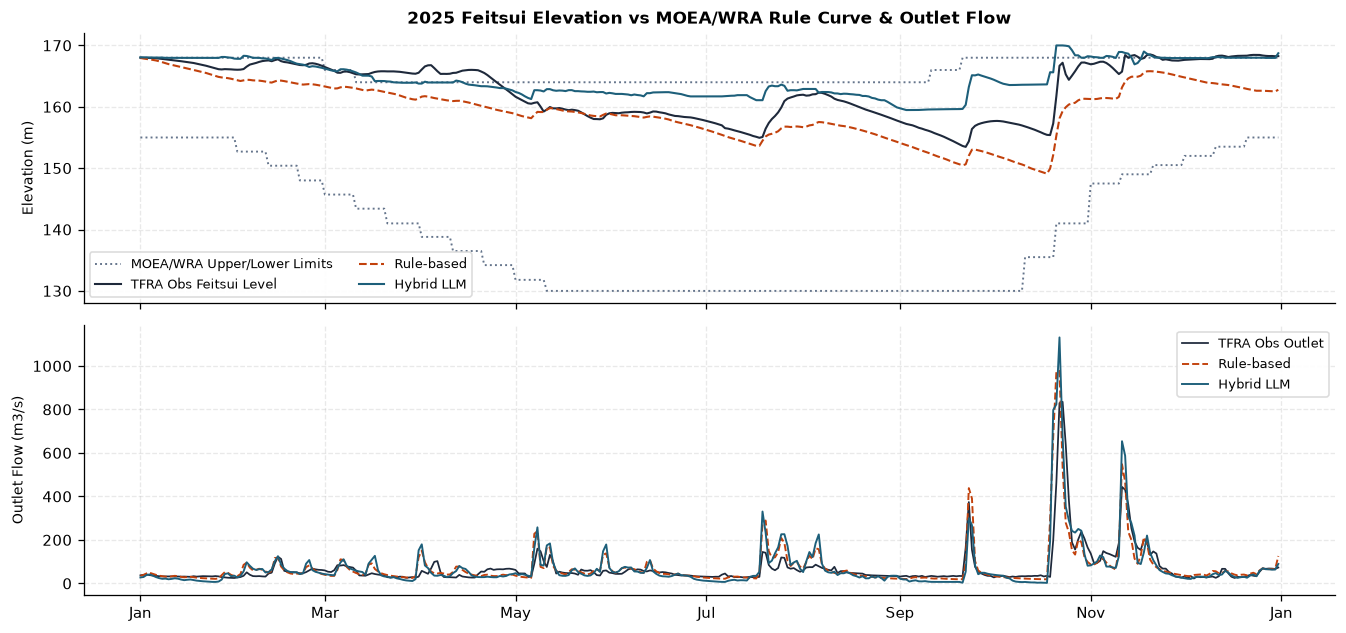

In [4]:
obs, rc = xd["observations"], xd["rule_curve_daily"]
_, _, to_elev = h.load_feitsui_curve(REPO_ROOT)
fig, axes = plt.subplots(2, 1, figsize=(11.8, 5.6), sharex=True)
axes[0].plot(rc.index, rc["upper_limit_m"], color=C["muted"], ls=":", lw=1.2, label="MOEA/WRA Upper/Lower Limits")
axes[0].plot(rc.index, rc["lower_limit_m"], color=C["muted"], ls=":", lw=1.2)
axes[0].plot(obs["date_dt"], obs["feitsui_elevation_m"], color=C["obs"], lw=1.3, label="TFRA Obs Feitsui Level")
for df, col, ls, lbl in [(r_tr, C["coral"], "--", "Rule-based"), (h_tr, C["teal"], "-", "Hybrid LLM")]:
    ft = df[(df["reservoir_id"] == "feitsui") & (df["date_key"] >= "2025-01-01")].copy()
    axes[0].plot(ft["date_dt"], [to_elev(v) for v in ft["storage_end_m3"]], color=col, ls=ls, lw=1.3, label=lbl)
axes[0].set_ylabel("Elevation (m)"); axes[0].set_title("2025 Feitsui Elevation vs MOEA/WRA Rule Curve & Outlet Flow"); axes[0].legend(fontsize=8, ncol=2)

axes[1].plot(obs["date_dt"], obs["downstream_flow_cms"], color=C["obs"], lw=1.1, label="TFRA Obs Outlet")
for df, col, ls, lbl in [(r_fl, C["coral"], "--", "Rule-based"), (h_fl, C["teal"], "-", "Hybrid LLM")]:
    out = df[(df["node"] == "xindian_outlet") & (df["date_key"] >= "2025-01-01")]
    axes[1].plot(out["date_dt"], out["routed_flow_cms"], color=col, ls=ls, lw=1.2, label=lbl)
axes[1].set_ylabel("Outlet Flow (m3/s)"); axes[1].legend(fontsize=8)
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=2)); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
plt.tight_layout(); plt.show()